In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Setup project directories for GitHub organization
DATA_DIR, IMAGE_DIR = "data", "images"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(IMAGE_DIR, exist_ok=True)

# Define uniform corporate styling colors
COLOR_REV = '#4285F4'  # Professional Blue
COLOR_EXP = '#EA4335'  # Strategic Red
COLOR_TEXT = '#5f6368' # Soft Charcoal

print("✓ Environment initialized. Target folders ready.")


✓ Environment initialized. Target folders ready.


In [2]:
# =====================================================================
# STEP 2: DYNAMIC DATA INGESTION FROM TITAN DATASET
# =====================================================================
# Define the precise path to your uploaded Titan spreadsheet
FILE_PATH = os.path.join(DATA_DIR, "Titan_Historical_Data.csv")

# Read your uploaded file using Pandas
raw_df = pd.read_csv(FILE_PATH)

# Clean numeric values by removing commas and extra spaces from the specific columns
# This matches the column headers from your dataset
for col in ['Revenue from Operations (Cr)', 'Total Expenses (Cr)']:
    if raw_df[col].dtype == 'object':
        raw_df[col] = raw_df[col].astype(str).str.replace(',', '').str.strip().astype(float)

# Extract structured variables dynamically from your live file
years_historical = raw_df['Financial year'].values
rev_historical = raw_df['Revenue from Operations (Cr)'].values
exp_historical = raw_df['Total Expenses (Cr)'].values

# Set up target prediction horizon (2027 to 2030)
years_forecast = np.array([2027, 2028, 2029, 2030])
years_combined = np.concatenate((years_historical, years_forecast))

# Reshape matrices for LinearRegression tracking compatibility
X_train = years_historical.reshape(-1, 1)
X_future = years_forecast.reshape(-1, 1)

print("✓ Ingestion Success: Connected directly to 'Titan_Historical_Data.csv'!")
print(f"  --> Extracted timeline sequence: {list(years_historical)}")
print(f"  --> Core baseline rows captured: {len(raw_df)} periods analyzed.")


✓ Ingestion Success: Connected directly to 'Titan_Historical_Data.csv'!
  --> Extracted timeline sequence: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
  --> Core baseline rows captured: 5 periods analyzed.


In [3]:
# =====================================================================
# STEP 3: PREDICTIVE FORECASTING ENGINE
# =====================================================================

# Initialize and fit individual Linear Regression trend engines
engine_revenue = LinearRegression().fit(X_train, rev_historical)
engine_expenses = LinearRegression().fit(X_train, exp_historical)

# Generate baseline projection steps for 2027, 2028, 2029, and 2030
rev_predicted = engine_revenue.predict(X_future)
exp_predicted = engine_expenses.predict(X_future)

# Display diagnostic summary report table
print("=================== TITAN FORECAST VALIDATION REPORT ===================")
print(f"{'Year':<8} | {'Projected Revenue (Cr)':<22} | {'Projected Expenses (Cr)':<22}")
print("-" * 58)
for i, yr in enumerate(years_forecast):
    print(f"{yr:<8} | {rev_predicted[i]:<22,.2f} | {exp_predicted[i]:<22,.2f}")
print("========================================================================\n")
print("✓ Step 3 Success: Model projections computed.")


=================== TITAN FORECAST VALIDATION REPORT ===================
Year     | Projected Revenue (Cr) | Projected Expenses (Cr)
----------------------------------------------------------
2027     | 84,176.00              | 78,272.40             
2028     | 95,902.00              | 89,413.20             
2029     | 107,628.00             | 100,554.00            
2030     | 119,354.00             | 111,694.80            

✓ Step 3 Success: Model projections computed.


In [4]:
# =====================================================================
# STEP 4: VISUAL DATA STREAM CONFIGURATION
# =====================================================================

# Create blank spacer arrays to prevent data crossover
nan_pad = [np.nan] * len(years_forecast)

# Revenue plot streams alignment
stream_rev_hist = np.append(rev_historical, nan_pad)
stream_rev_fore = np.append([np.nan] * (len(years_historical) - 1), [rev_historical[-1]])
stream_rev_fore = np.append(stream_rev_fore, rev_predicted)

# Expense plot streams alignment
stream_exp_hist = np.append(exp_historical, nan_pad)
stream_exp_fore = np.append([np.nan] * (len(years_historical) - 1), [exp_historical[-1]])
stream_exp_fore = np.append(stream_exp_fore, exp_predicted)

print("✓ Step 4 Success: Visual data timelines synchronized for graph rendering.")


✓ Step 4 Success: Visual data timelines synchronized for graph rendering.


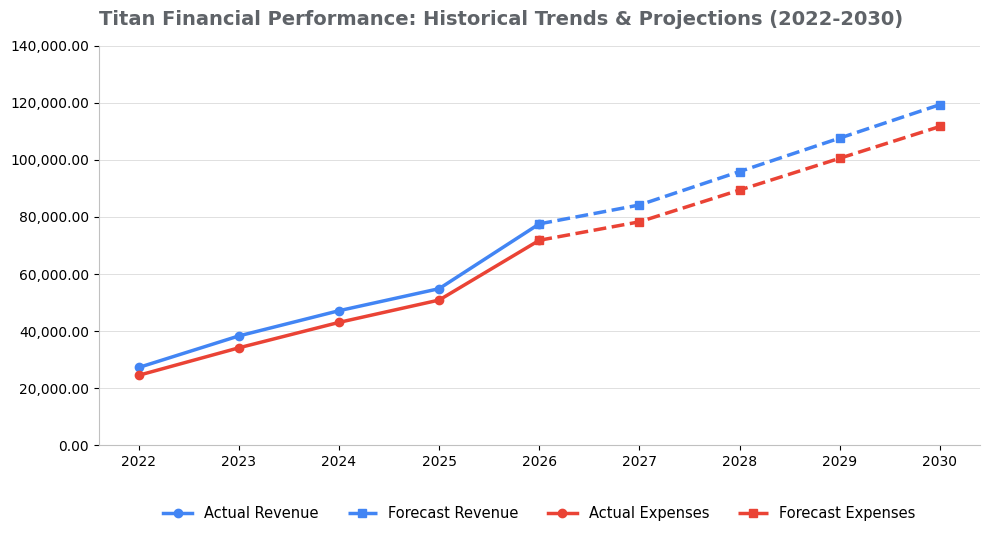

In [5]:
# =====================================================================
# STEP 5: CORE FINANCIAL PERFORMANCE CHART (COMBINED)
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='white')
ax.set_facecolor('white')

# Plot structural paths (Solid lines for history, Dashed lines for forecast)
ax.plot(years_combined, stream_rev_hist, color=COLOR_REV, marker='o', linewidth=2.5, label='Actual Revenue')
ax.plot(years_combined, stream_rev_fore, color=COLOR_REV, linestyle='--', marker='s', linewidth=2.5, label='Forecast Revenue')
ax.plot(years_combined, stream_exp_hist, color=COLOR_EXP, marker='o', linewidth=2.5, label='Actual Expenses')
ax.plot(years_combined, stream_exp_fore, color=COLOR_EXP, linestyle='--', marker='s', linewidth=2.5, label='Forecast Expenses')

# Polishing layouts and titles
ax.set_title("Titan Financial Performance: Historical Trends & Projections (2022-2030)", fontsize=14, fontweight='bold', color=COLOR_TEXT, pad=15, loc='left')
ax.set_ylim(0, 140000)
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:,.2f}" if x > 0 else "0.00"))
ax.grid(axis='y', linestyle='-', linewidth=0.7, color='#e0e0e0')

# Clear boundaries to match clean corporate standards
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#c0c0c0')
ax.spines['bottom'].set_color('#c0c0c0')

# Position the legend perfectly below the chart boundary
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=10.5)

plt.tight_layout()
plt.savefig(f'{IMAGE_DIR}/1_combined_forecast.png', dpi=300, bbox_inches='tight')
plt.show()


--------------------- PROFIT MARGIN TRAJECTORY --------------------
Year 2022 | Margin: 10.06%
Year 2023 | Margin: 10.89%
Year 2024 | Margin: 8.70%
Year 2025 | Margin: 7.27%
Year 2026 | Margin: 7.42%
Year 2027 | Margin: 7.01%
Year 2028 | Margin: 6.77%
Year 2029 | Margin: 6.57%
Year 2030 | Margin: 6.42%
------------------------------------------------------------------



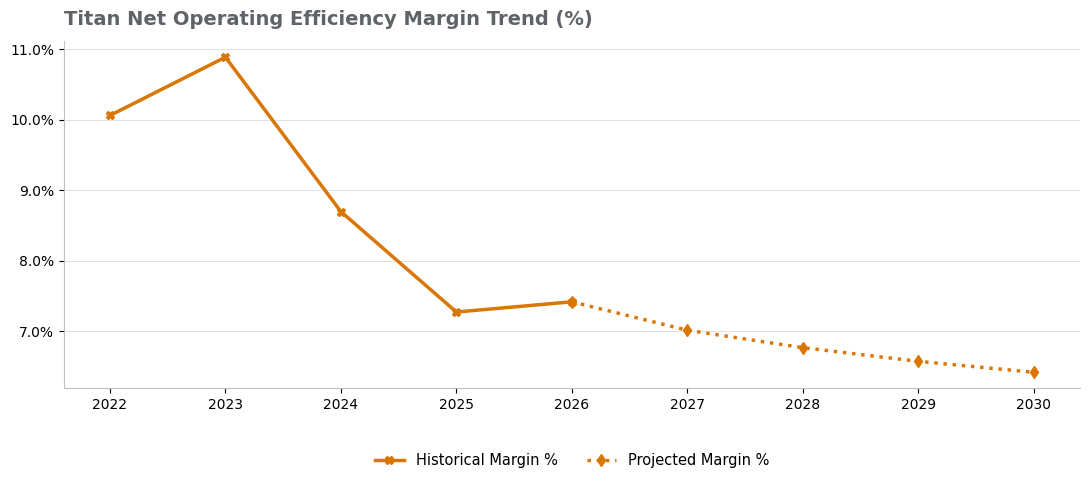

✓ Step 7 Success: Operating efficiency profiles generated with updated color profile.


In [7]:
# =====================================================================
# STEP 7: NET OPERATING PROFIT MARGIN PERFORMANCE TIMELINE
# =====================================================================

# Calculate margin percentages: ((Revenue - Expenses) / Revenue) * 100
historical_margins = ((rev_historical - exp_historical) / rev_historical) * 100
predicted_margins = ((rev_predicted - exp_predicted) / rev_predicted) * 100
combined_margins = np.concatenate((historical_margins, predicted_margins))

# Initialize canvas layout
fig, ax = plt.subplots(figsize=(11, 5), facecolor='white')
ax.set_facecolor('white')

# Set up clean plotting streams for connected lines
stream_margin_hist = np.append(historical_margins, [np.nan] * len(years_forecast))
stream_margin_fore = np.append([np.nan] * (len(years_historical) - 1), [historical_margins[-1]])
stream_margin_fore = np.append(stream_margin_fore, predicted_margins)

# Plot timeline paths using a Premium Corporate Gold / Amber theme
COLOR_MARGIN = '#D97706'  # Elegant Amber/Gold Accent

ax.plot(years_combined, stream_margin_hist, color=COLOR_MARGIN, marker='X', markersize=6, linewidth=2.5, label='Historical Margin %')
ax.plot(years_combined, stream_margin_fore, color=COLOR_MARGIN, linestyle=':', marker='d', markersize=6, linewidth=2.5, label='Projected Margin %')

# Polishing scales and labels
ax.set_title("Titan Net Operating Efficiency Margin Trend (%)", fontsize=14, fontweight='bold', color=COLOR_TEXT, pad=12, loc='left')
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.1f}%"))
ax.grid(axis='y', linestyle='-', linewidth=0.7, color='#e0e0e0')

# Clear boundaries
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#c0c0c0')
ax.spines['bottom'].set_color('#c0c0c0')

# Place legend
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=10.5)

# Display diagnostic readout in notebook terminal
print("--------------------- PROFIT MARGIN TRAJECTORY --------------------")
for i, yr in enumerate(years_combined):
    print(f"Year {yr} | Margin: {combined_margins[i]:.2f}%")
print("------------------------------------------------------------------\n")

plt.tight_layout()
plt.savefig(f'{IMAGE_DIR}/4_profit_margin_trend.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Step 7 Success: Operating efficiency profiles generated with updated color profile.")


In [8]:
# =====================================================================
# STEP 8: ARCHIVE FILES FOR PROJECT EXPORT
# =====================================================================
import shutil

# Target archive folder name
archive_output_name = "Titan_Forecasting_Project_Files"

# Compress images and data folders into a single deployable ZIP bundle
shutil.make_archive(archive_output_name, 'zip', base_dir='images')
shutil.copy('data/Titan_Historical_Data.csv', '.')

print(f"✓ Step 8 Success: Compilation complete.")
print(f"  --> Download file bundle ready: '{archive_output_name}.zip'")


✓ Step 8 Success: Compilation complete.
  --> Download file bundle ready: 'Titan_Forecasting_Project_Files.zip'
